# 2. Lấy mẫu đều và lựa chọn mẫu dễ/xa biên

Notebook thực nghiệm bốn thuật toán thuộc nhóm undersampling:

1. **Random UnderSampling (RUS)**
2. **Cluster Centroids**
3. **Condensed Nearest Neighbours (CNN)**
4. **One-Sided Selection (OSS)**

Các hàm dùng chung như tạo dữ liệu, khởi tạo sampler, vẽ biểu đồ và lưu kết quả được gọi trực tiếp từ `utils.py`. Notebook chỉ giữ lại phần điều phối thực nghiệm và diễn giải kết quả.

## 1. Khởi tạo môi trường và import `utils.py`

In [19]:
# === CELL KHOI TAO MOI TRUONG CHUNG ===
import os, sys

# Them thu muc goc vao sys.path de import duoc module src.utils
root_dir = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
if root_dir not in sys.path:
    sys.path.insert(0, root_dir)

from src.utils import (
    RANDOM_STATE,
    load_synthetic_data,
    load_real_data,
    get_all_undersamplers,
    get_benchmark_models,
    plot_resampled_comparison,
    plot_decision_boundary,
    plot_pr_curve,
    evaluate_sampler_and_model,
    get_output_dirs,
    save_figure,
    save_table
)
get_output_dirs()  # Tao san outputs/figures va outputs/tables neu chua ton tai
print('Khoi tao thanh cong! Thu muc goc:', root_dir)

Khoi tao thanh cong! Thu muc goc: f:\PR\PR_Seminar_Undersampling


## 2. Chuẩn bị dữ liệu

Sử dụng hàm `load_synthetic_data()` trong `utils.py`. Hàm tạo dữ liệu phân loại nhị phân 2 chiều với tỷ lệ mất cân bằng 1:99, sau đó chia train/test bằng `stratify` để giữ tỷ lệ lớp.

Chỉ thực hiện undersampling trên tập train. Tập test được giữ nguyên để tránh rò rỉ dữ liệu và bảo đảm việc so sánh.

In [20]:
X_train, X_test, y_train, y_test, X, y = load_synthetic_data()

print("Kích thước X_train:", X_train.shape)
print("Kích thước X_test :", X_test.shape)
print("\\nPhân bố lớp train:")
print(y_train.value_counts().sort_index())
print("\\nPhân bố lớp test:")
print(y_test.value_counts().sort_index())

Kích thước X_train: (8000, 2)
Kích thước X_test : (2000, 2)
\nPhân bố lớp train:
target
0    7920
1      80
Name: count, dtype: int64
\nPhân bố lớp test:
target
0    1980
1      20
Name: count, dtype: int64


## 3. Khởi tạo các thuật toán

`get_all_undersamplers(include_slow=True)` trả về các sampler đã được cấu hình thống nhất trong `utils.py`. Notebook chỉ lựa chọn bốn thuật toán thuộc phạm vi nội dung này.

- `RandomUS`: Random UnderSampling.
- `ClusterCentroids`: Cluster Centroids.
- `CNN`: Condensed Nearest Neighbours.
- `OSS`: One-Sided Selection.

In [21]:
all_samplers = get_all_undersamplers(include_slow=True)

samplers = {
    "Random UnderSampling (RUS)": all_samplers["RandomUS"],
    "Cluster Centroids": all_samplers["ClusterCentroids"],
    "Condensed Nearest Neighbours (CNN)": all_samplers["CNN"],
    "One-Sided Selection (OSS)": all_samplers["OSS"],
}

print("Các thuật toán sẽ chạy:")
for name in samplers:
    print("-", name)

Các thuật toán sẽ chạy:
- Random UnderSampling (RUS)
- Cluster Centroids
- Condensed Nearest Neighbours (CNN)
- One-Sided Selection (OSS)


## 4. Hàm thực nghiệm dùng chung

Hàm dưới đây thực hiện lần lượt:

1. Fit sampler trên tập train và tạo dữ liệu sau undersampling.
2. Gọi `utils.plot_resampled_comparison()` để so sánh phân bố trước/sau.
3. Gọi `utils.save_figure()` để lưu biểu đồ.
4. Huấn luyện Logistic Regression trên dữ liệu sau undersampling.
5. Gọi `utils.plot_decision_boundary()` để trực quan hóa ranh giới phân loại.
6. Ghi nhận số lượng mẫu và thời gian xử lý.

Như vậy, các hàm vẽ và lưu hình đều được tái sử dụng từ `utils.py`, không định nghĩa lại trong notebook.

In [22]:
import matplotlib.pyplot as plt

from collections import Counter
from time import perf_counter

results = []
resampled_data = {}

def run_method(method_name, sampler):
    start_time = perf_counter()

    X_resampled, y_resampled = sampler.fit_resample(X_train, y_train)

    elapsed = perf_counter() - start_time
    resampled_data[method_name] = (X_resampled, y_resampled)

    # Biểu đồ phân bố dữ liệu trước và sau undersampling
    fig = plot_resampled_comparison(
        X_train, y_train,
        X_resampled, y_resampled,
        method_name
    )
    save_figure(fig, method_name.replace(" ", "_") + "_scatter")
    plt.show()
    plt.close(fig)

    # Huấn luyện Logistic Regression trên dữ liệu sau undersampling
    model = get_benchmark_models()["LogisticRegression"]
    model.fit(X_resampled, y_resampled)

    # Decision Boundary trên tập dữ liệu sau undersampling
    fig, ax = plt.subplots(figsize=(7, 5))
    plot_decision_boundary(
        X_resampled, y_resampled, model,
        classifier_name=method_name,
        ax=ax
    )
    save_figure(fig, method_name.replace(" ", "_") + "_decision_boundary")
    plt.show()
    plt.close(fig)

    before_counts = Counter(y_train)
    after_counts = Counter(y_resampled)

    result = {
        "Algorithm": method_name,
        "Before - Class 0": before_counts.get(0, 0),
        "Before - Class 1": before_counts.get(1, 0),
        "After - Class 0": after_counts.get(0, 0),
        "After - Class 1": after_counts.get(1, 0),
        "Samples before": len(y_train),
        "Samples after": len(y_resampled),
        "Reduction (%)": round((1 - len(y_resampled) / len(y_train)) * 100, 2),
        "Sampling time (s)": round(elapsed, 4)
    }
    results.append(result)

    print(f"Hoàn thành: {method_name}")
    print("Phân bố trước:", dict(before_counts))
    print("Phân bố sau  :", dict(after_counts))
    print(f"Thời gian lấy mẫu: {elapsed:.4f} giây")

    return X_resampled, y_resampled

## 5. Random UnderSampling (RUS)

Random UnderSampling loại bỏ ngẫu nhiên một số mẫu thuộc **lớp đa số**. Các mẫu lớp thiểu số được giữ lại. Phương pháp có thể giảm nhanh số lượng dữ liệu nhưng cũng có nguy cơ loại bỏ những mẫu lớp đa số có ích.

Thực hiện thuật toán và quan sát hai biểu đồ: phân bố dữ liệu trước/sau undersampling và Decision Boundary.

Đã lưu đồ thị tại: f:\PR\PR_Seminar_Undersampling\outputs\figures\Random_UnderSampling_(RUS)_scatter.png


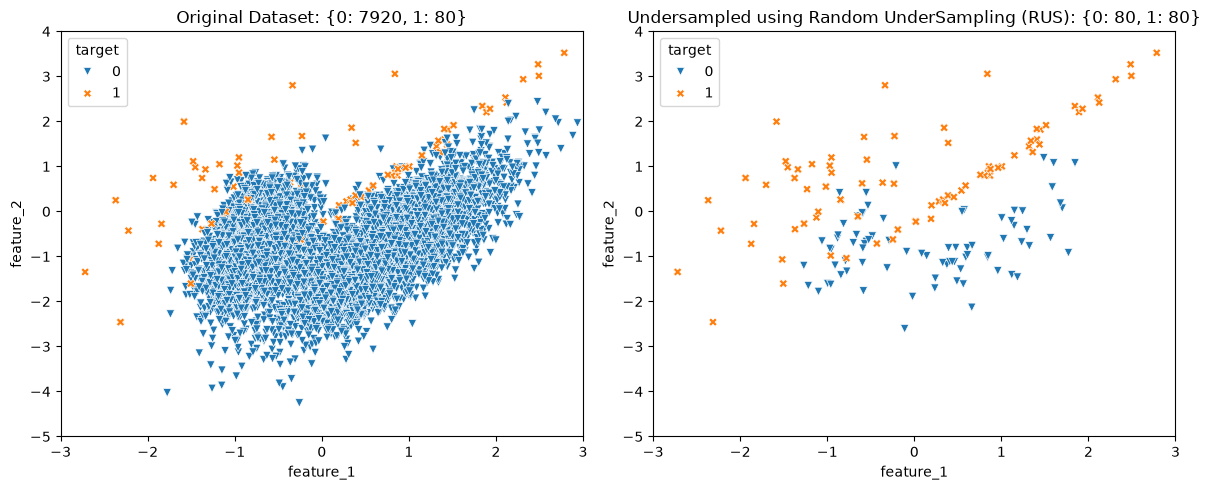

f:\anaconda\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


Đã lưu đồ thị tại: f:\PR\PR_Seminar_Undersampling\outputs\figures\Random_UnderSampling_(RUS)_decision_boundary.png


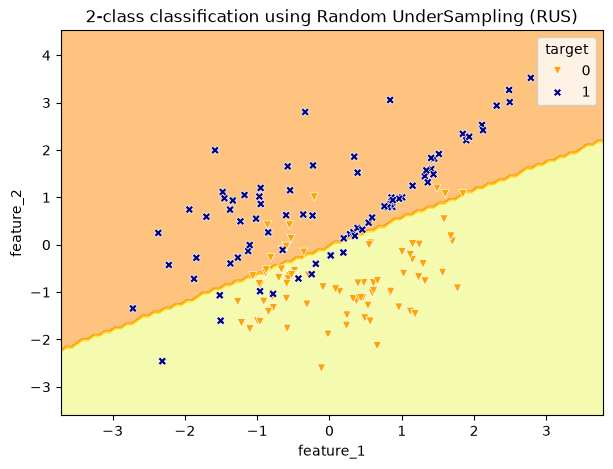

Hoàn thành: Random UnderSampling (RUS)
Phân bố trước: {0: 7920, 1: 80}
Phân bố sau  : {0: 80, 1: 80}
Thời gian lấy mẫu: 0.0040 giây


In [23]:
X_resampled, y_resampled = run_method(
    "Random UnderSampling (RUS)",
    samplers["Random UnderSampling (RUS)"]
)

## 6. Cluster Centroids

Cluster Centroids đại diện các cụm của lớp đa số bằng những tâm cụm (centroids). Các điểm sau lấy mẫu có thể là điểm tổng hợp, không nhất thiết trùng với một quan sát ban đầu. Phương pháp giúp cô đọng dữ liệu nhưng có thể làm thay đổi cấu trúc phân bố.

Thực hiện thuật toán và quan sát hai biểu đồ: phân bố dữ liệu trước/sau undersampling và Decision Boundary.

Đã lưu đồ thị tại: f:\PR\PR_Seminar_Undersampling\outputs\figures\Cluster_Centroids_scatter.png


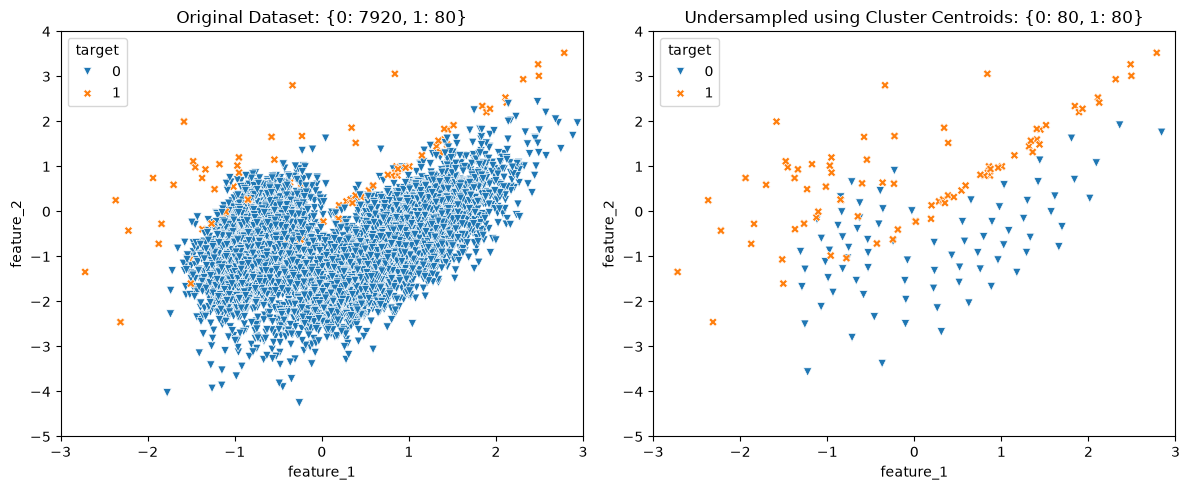

f:\anaconda\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


Đã lưu đồ thị tại: f:\PR\PR_Seminar_Undersampling\outputs\figures\Cluster_Centroids_decision_boundary.png


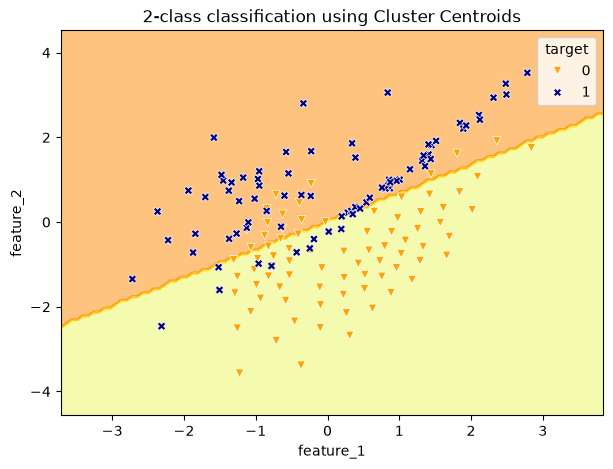

Hoàn thành: Cluster Centroids
Phân bố trước: {0: 7920, 1: 80}
Phân bố sau  : {0: 80, 1: 80}
Thời gian lấy mẫu: 0.0391 giây


In [24]:
X_resampled, y_resampled = run_method(
    "Cluster Centroids",
    samplers["Cluster Centroids"]
)

## 7. Condensed Nearest Neighbours (CNN)

CNN xây dựng một tập con đại diện phục vụ quy tắc phân loại láng giềng gần nhất. Những mẫu không cần thiết cho tập đại diện có thể bị loại bỏ. Kết quả thường phụ thuộc vào cấu trúc dữ liệu và không nhất thiết đạt tỷ lệ cân bằng 1:1.

Thực hiện thuật toán và quan sát hai biểu đồ: phân bố dữ liệu trước/sau undersampling và Decision Boundary.

Đã lưu đồ thị tại: f:\PR\PR_Seminar_Undersampling\outputs\figures\Condensed_Nearest_Neighbours_(CNN)_scatter.png


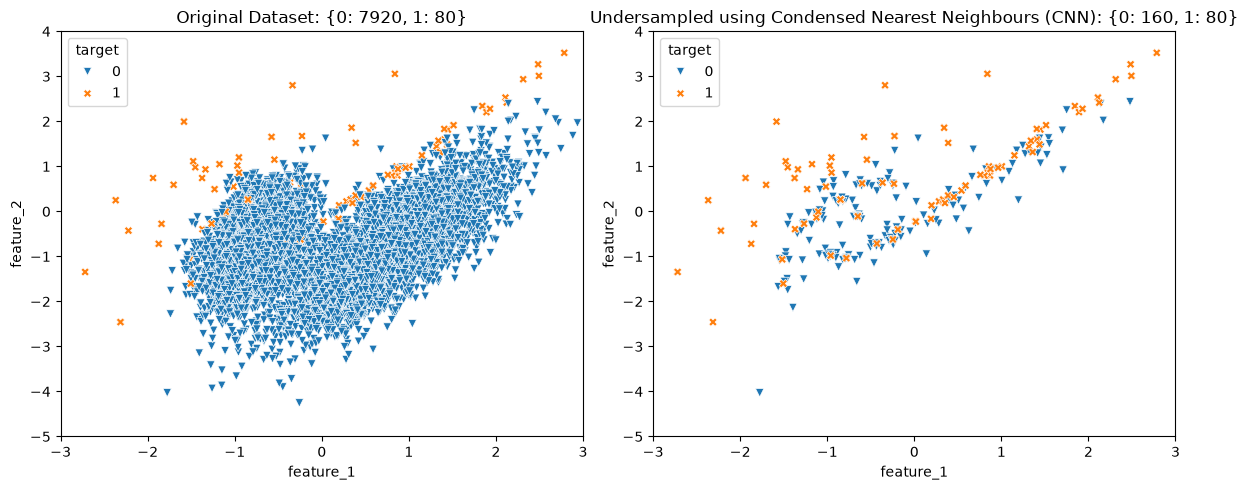

f:\anaconda\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


Đã lưu đồ thị tại: f:\PR\PR_Seminar_Undersampling\outputs\figures\Condensed_Nearest_Neighbours_(CNN)_decision_boundary.png


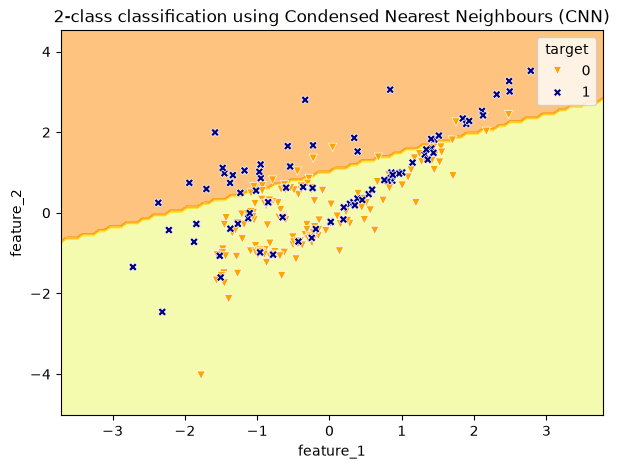

Hoàn thành: Condensed Nearest Neighbours (CNN)
Phân bố trước: {0: 7920, 1: 80}
Phân bố sau  : {0: 160, 1: 80}
Thời gian lấy mẫu: 0.9471 giây


In [25]:
X_resampled, y_resampled = run_method(
    "Condensed Nearest Neighbours (CNN)",
    samplers["Condensed Nearest Neighbours (CNN)"]
)

## 8. One-Sided Selection (OSS)

OSS kết hợp lựa chọn mẫu đại diện với loại bỏ một số mẫu lớp đa số dư thừa hoặc gây nhiễu. Phương pháp hướng tới việc giữ lại các mẫu quan trọng, đặc biệt quanh vùng phân cách giữa các lớp. OSS không bắt buộc tạo ra hai lớp có số lượng bằng nhau.

Thực hiện thuật toán và quan sát hai biểu đồ: phân bố dữ liệu trước/sau undersampling và Decision Boundary.

Đã lưu đồ thị tại: f:\PR\PR_Seminar_Undersampling\outputs\figures\One-Sided_Selection_(OSS)_scatter.png


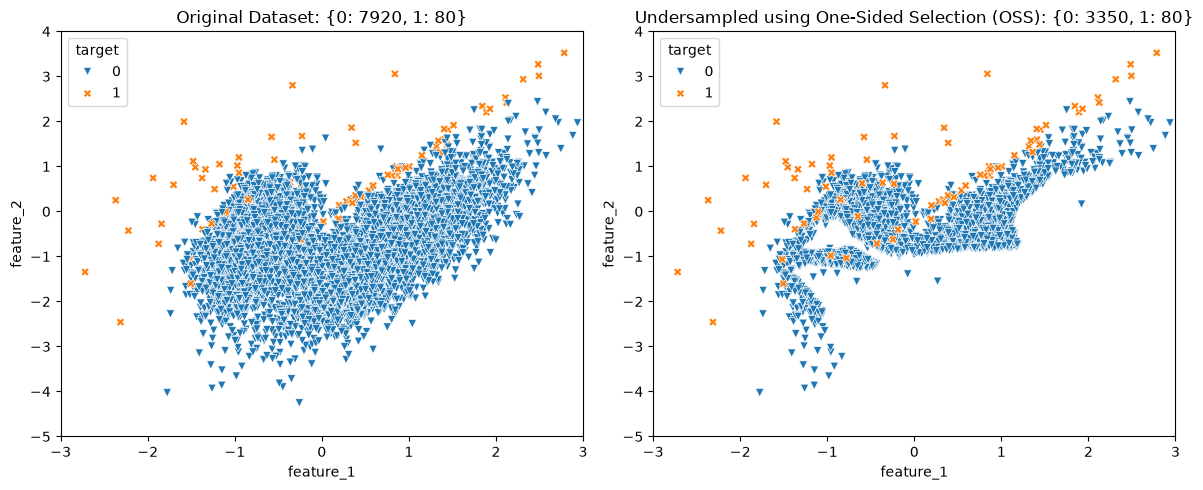

f:\anaconda\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


Đã lưu đồ thị tại: f:\PR\PR_Seminar_Undersampling\outputs\figures\One-Sided_Selection_(OSS)_decision_boundary.png


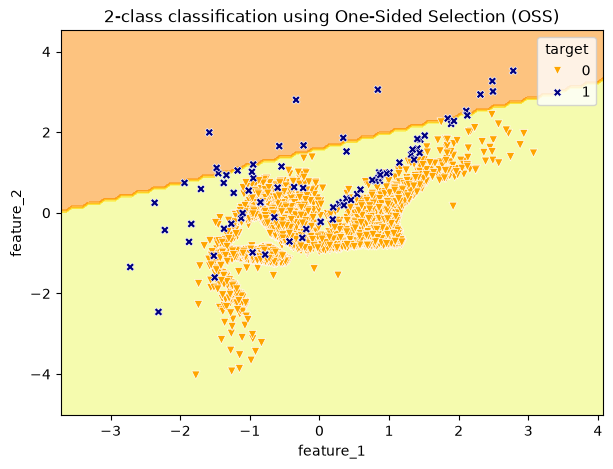

Hoàn thành: One-Sided Selection (OSS)
Phân bố trước: {0: 7920, 1: 80}
Phân bố sau  : {0: 3350, 1: 80}
Thời gian lấy mẫu: 0.0301 giây


In [26]:
X_resampled, y_resampled = run_method(
    "One-Sided Selection (OSS)",
    samplers["One-Sided Selection (OSS)"]
)

## 9. Tổng hợp và so sánh

Bảng dưới đây tổng hợp số lượng mẫu trước/sau, mức giảm dữ liệu và thời gian thực hiện lấy mẫu của bốn thuật toán.

In [27]:
import pandas as pd

results_df = pd.DataFrame(results)
display(results_df)

# Lưu bảng tổng hợp bằng hàm dùng chung trong utils.py
save_table(results_df, "02_uniform_and_easy_samples_summary")

,Algorithm,Before - Class 0,Before - Class 1,After - Class 0,After - Class 1,Samples before,Samples after,Reduction (%),Sampling time (s)
0,Random UnderSampling (RUS),7920,80,80,80,8000,160,98.00,0.0040
1,Cluster Centroids,7920,80,80,80,8000,160,98.00,0.0391
2,Condensed Nearest Neighbours (CNN),7920,80,160,80,8000,240,97.00,0.9471
3,One-Sided Selection (OSS),7920,80,3350,80,8000,3430,57.12,0.0301


Đã lưu bảng số liệu tại: f:\PR\PR_Seminar_Undersampling\outputs\tables\02_uniform_and_easy_samples_summary.csv


'f:\\PR\\PR_Seminar_Undersampling\\outputs\\tables\\02_uniform_and_easy_samples_summary.csv'

### Tiêu chí nhận xét

1. **Số lượng mẫu:** thuật toán giảm được bao nhiêu mẫu lớp đa số?
2. **Bảo toàn lớp thiểu số:** số mẫu lớp thiểu số có được giữ nguyên không?
3. **Phân bố dữ liệu:** hình dạng và vùng tập trung của dữ liệu thay đổi như thế nào?
4. **Ranh giới phân loại:** Decision Boundary thay đổi ra sao sau undersampling?
5. **Thời gian xử lý:** thuật toán nào có chi phí tính toán cao hơn?

> Các biểu đồ trong notebook dùng để quan sát tác động của undersampling. Chúng không thay thế cho đánh giá định lượng mô hình trên tập test bằng Precision, Recall, F1-score, PR-AUC hoặc ROC-AUC.